# Preserved-Site (TSS-Exclusive) 5-Fold Reorganization & Per-Fold Macenko Reference Standards (`qc_v5_fold_proposal`)

This notebook reorganizes your **TCGA** cohort across `A_qc-v5` and `B_qc-v5` using **Preserved-Site Stratified Cross-Validation** (Howard et al., 2021) and builds a **fold-specific Macenko stain normalization reference standard** for each fold (`0`–`4`) without cross-fold leakage:
1. **Zero site leakage:** Every patient from a single Tissue Source Site (TSS / submitting institution) belongs exclusively to **one** fold (`0`–`4`).
2. **Balanced class & fold sizes:** Folds `0`–`4` are jointly optimized via Mixed-Integer Linear Programming (MILP) to balance total TCGA patient count and *MGMT* `Methylated` vs. `Unmethylated` ratio.
3. **Per-fold Macenko reference standard (`25` patches/slide in each fold):** For each fold `k` (`0`–`4`), samples up to `25` stored tissue patches per slide across all TCGA slides in fold `k`, fits the Macenko H&E optical density stain matrix (`2 x 3`) and 99th-percentile stain concentrations (`maxC`, shape `(2,)`), and saves:
   - `qc_v5_fold_proposal_macenko_fold_{k}.npz` (per-fold Macenko reference matrices & target image)
   - `qc_v5_fold_proposal_macenko_summary.csv` (per-fold stain vectors, `maxC` percentiles, slide/patch counts)
4. **Drop-in pipeline manifests & chart:**
   - `qc_v5_fold_proposal_folds.csv`
   - `qc_v5_fold_proposal_labels.csv`
   - `qc_v5_fold_proposal_index.csv` (master + inside `A_qc-v5` and `B_qc-v5`)
   - `qc_v5_fold_proposal_site_summary.csv`
   - `qc_v5_fold_proposal_chart.png`

In [6]:
from pathlib import Path
import re
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.optimize import milp, LinearConstraint, Bounds

# --- 1. Paths & Configuration ---
MANIFESTS_DIR = Path("/Users/couger/gbm-mgmt-wsi/manifests")
LABELS_CSV = MANIFESTS_DIR / "patient_labels.csv"
FOLDS_CSV = MANIFESTS_DIR / "patient_folds.csv"
MASTER_INDEX_CSV = MANIFESTS_DIR / "patient_index.csv"

PACKAGES_ROOT = Path("/Volumes/Expansion/pathology_data/packages")
PACKAGE_NAMES = ["A_qc-v5", "B_qc-v5"]

# Output directory & prefix
OUT_DIR = MANIFESTS_DIR
MACENKO_OUT_DIR = OUT_DIR / "qc_v5_fold_proposal_macenko"
PREFIX = "qc_v5_fold_proposal"
N_FOLDS = 5
INCLUDE_EXTERNAL_IN_FILES = True  # Preserves CPTAC/external rows as fold='external' in output manifests

# Macenko reference standard parameters
PATCHES_PER_SLIDE = 25
RANDOM_SEED = 42
MACENKO_I0 = 240.0       # Transmitted light intensity
MACENKO_BETA = 0.15      # OD threshold for transparent/background pixels
MACENKO_ALPHA = 1.0      # Percentile for robust min/max angle estimation
MAX_OD_PIXELS_PER_PATCH = 4096  # Subsample foreground pixels per patch for fast, exact SVD

TSS_TO_INSTITUTION = {
    "02": "MD Anderson Cancer Center",
    "06": "Henry Ford Hospital",
    "08": "UCSF",
    "12": "Duke",
    "14": "Emory University",
    "15": "Mayo Clinic - Rochester",
    "19": "Case Western",
    "26": "University of Florida",
    "27": "Fondazione IRCCS Carlo Besta",
    "28": "Cedars-Sinai",
    "32": "St. Joseph's Hospital (AZ)",
    "41": "Moffitt Cancer Center",
    "76": "Memorial Sloan Kettering",
    "87": "University of Alabama at Birmingham",
}

TCGA_TSS_RE = re.compile(r"\bTCGA-([0-9A-Z]{2})-[0-9A-Z]{4}", re.IGNORECASE)

def extract_tcga_tss(val: str) -> str | None:
    if not isinstance(val, str):
        return None
    m = TCGA_TSS_RE.search(val)
    if m:
        return m.group(1).upper()
    parts = val.strip().split("-")
    if len(parts) >= 2 and parts[0].upper() == "TCGA" and len(parts[1]) == 2:
        return parts[1].upper()
    return None

def norm_mgmt(val) -> str | None:
    if pd.isna(val):
        return None
    s = str(val).strip().lower()
    if s in {"1", "m", "methylated", "pos", "positive", "true"}:
        return "Methylated"
    if s in {"0", "u", "unmethylated", "neg", "negative", "false"}:
        return "Unmethylated"
    if "unmethyl" in s:
        return "Unmethylated"
    if "methyl" in s:
        return "Methylated"
    return None

In [7]:
# --- 2. Load TCGA Cohort Across A_qc-v5 & B_qc-v5 (Strictly Excluding CPTAC from Folds 0-4) ---
folds_raw = pd.read_csv(FOLDS_CSV, dtype={"fold": str}, low_memory=False)
labels_raw = pd.read_csv(LABELS_CSV, low_memory=False)

pkg_frames = []
for pkg in PACKAGE_NAMES:
    p_idx = PACKAGES_ROOT / pkg / "patient_index.csv"
    if p_idx.exists():
        df_p = pd.read_csv(p_idx, dtype={"fold": str}, low_memory=False)
        df_p["package"] = pkg
        pkg_frames.append(df_p)

if pkg_frames:
    pkg_all = pd.concat(pkg_frames, ignore_index=True)
    tcga_pkg_ids = set(
        pkg_all[pkg_all["source"].astype(str).str.upper() == "TCGA"]["patient_id"].astype(str).str.strip()
    )
else:
    tcga_pkg_ids = None

tcga_folds = folds_raw[folds_raw["source"].astype(str).str.upper() == "TCGA"].copy()
tcga_folds["patient_id"] = tcga_folds["patient_id"].astype(str).str.strip()
tcga_folds["fold"] = tcga_folds["fold"].astype(str).str.strip()
tcga_folds = tcga_folds.drop_duplicates(subset=["patient_id"])

if tcga_pkg_ids is not None:
    tcga_folds = tcga_folds[tcga_folds["patient_id"].isin(tcga_pkg_ids)].copy()

tcga_labels = labels_raw[labels_raw["source"].astype(str).str.upper() == "TCGA"].copy()
tcga_labels["patient_id"] = tcga_labels["patient_id"].astype(str).str.strip()
tcga_labels["mgmt_clean"] = tcga_labels["mgmt_status"].apply(norm_mgmt)
tcga_labels = tcga_labels.drop_duplicates(subset=["patient_id"])

tcga_df = tcga_folds.merge(tcga_labels[["patient_id", "mgmt_status", "mgmt_clean"]], on="patient_id", how="inner")
tcga_df["tss_code"] = tcga_df["patient_id"].apply(extract_tcga_tss)
tcga_df = tcga_df[tcga_df["tss_code"].notna() & tcga_df["mgmt_clean"].isin(["Methylated", "Unmethylated"])].copy()
tcga_df["institution"] = tcga_df["tss_code"].apply(
    lambda c: f"{c} — {TSS_TO_INSTITUTION.get(c, 'Unknown TSS')}"
)

print(f"Eligible TCGA patients with known MGMT status: {len(tcga_df)}")
print(f"Unique TCGA Tissue Source Sites (TSS): {tcga_df['tss_code'].nunique()}")
display(tcga_df.groupby(["tss_code", "institution", "mgmt_clean"]).size().unstack(fill_value=0))

Eligible TCGA patients with known MGMT status: 151
Unique TCGA Tissue Source Sites (TSS): 11


,mgmt_clean,Methylated,Unmethylated
tss_code,institution,,
02,02 — MD Anderson Cancer Center,8,14
06,06 — Henry Ford Hospital,9,16
12,12 — Duke,9,15
14,14 — Emory University,11,8
15,15 — Mayo Clinic - Rochester,0,1
19,19 — Case Western,15,9
26,26 — University of Florida,0,2
27,27 — Fondazione IRCCS Carlo Besta,6,10
28,28 — Cedars-Sinai,3,6


In [8]:
# --- 3. Solve Preserved-Site Stratified 5-Fold Assignment (MILP / Exact Solver) ---
site_stats = (
    tcga_df.groupby(["tss_code", "institution"])
    .agg(
        n_total=("patient_id", "count"),
        n_meth=("mgmt_clean", lambda s: (s == "Methylated").sum()),
        n_unmeth=("mgmt_clean", lambda s: (s == "Unmethylated").sum()),
    )
    .reset_index()
    .sort_values(["n_total", "tss_code"], ascending=[False, True])
    .reset_index(drop=True)
)

S = len(site_stats)
K = N_FOLDS
if S < K:
    raise ValueError(f"Cannot assign {S} unique TSS sites exclusively across {K} folds.")

n_tot_vec = site_stats["n_total"].to_numpy(dtype=float)
n_meth_vec = site_stats["n_meth"].to_numpy(dtype=float)
n_unmeth_vec = site_stats["n_unmeth"].to_numpy(dtype=float)

target_tot = n_tot_vec.sum() / K
target_meth = n_meth_vec.sum() / K
target_unmeth = n_unmeth_vec.sum() / K

num_x = S * K
num_vars = num_x + 3 * K

c = np.zeros(num_vars)
c[num_x : num_x + K] = 1.0
c[num_x + K : num_x + 2 * K] = 1.5
c[num_x + 2 * K : num_x + 3 * K] = 1.5

integrality = np.zeros(num_vars)
integrality[:num_x] = 1

lb = np.zeros(num_vars)
ub = np.full(num_vars, np.inf)
ub[:num_x] = 1.0

rows_A, lhs, rhs = [], [], []

# Constraint 1: Each site s assigned to exactly one fold k
for s in range(S):
    row = np.zeros(num_vars)
    for k in range(K):
        row[s * K + k] = 1.0
    rows_A.append(row)
    lhs.append(1.0)
    rhs.append(1.0)

# Constraint 2: Each fold k receives at least 1 site
for k in range(K):
    row = np.zeros(num_vars)
    for s in range(S):
        row[s * K + k] = 1.0
    rows_A.append(row)
    lhs.append(1.0)
    rhs.append(np.inf)

# Constraint 3: Linearized L1 deviations for tot, meth, unmeth per fold
for k in range(K):
    for sign in (+1.0, -1.0):
        row = np.zeros(num_vars)
        for s in range(S):
            row[s * K + k] = sign * n_tot_vec[s]
        row[num_x + k] = -1.0
        rows_A.append(row)
        lhs.append(-np.inf)
        rhs.append(sign * target_tot)

    for sign in (+1.0, -1.0):
        row = np.zeros(num_vars)
        for s in range(S):
            row[s * K + k] = sign * n_meth_vec[s]
        row[num_x + K + k] = -1.0
        rows_A.append(row)
        lhs.append(-np.inf)
        rhs.append(sign * target_meth)

    for sign in (+1.0, -1.0):
        row = np.zeros(num_vars)
        for s in range(S):
            row[s * K + k] = sign * n_unmeth_vec[s]
        row[num_x + 2 * K + k] = -1.0
        rows_A.append(row)
        lhs.append(-np.inf)
        rhs.append(sign * target_unmeth)

res = milp(
    c=c,
    integrality=integrality,
    bounds=Bounds(lb, ub),
    constraints=LinearConstraint(np.array(rows_A), lhs, rhs),
)

if not res.success:
    raise RuntimeError(f"MILP fold optimization failed: {res.message}")

x_sol = np.rint(res.x[:num_x]).reshape(S, K).astype(int)
assigned_folds = [str(int(np.argmax(x_sol[s]))) for s in range(S)]
site_stats["assigned_fold"] = assigned_folds

tss_to_fold = dict(zip(site_stats["tss_code"], site_stats["assigned_fold"]))
tcga_df["new_fold"] = tcga_df["tss_code"].map(tss_to_fold)

leak_check = tcga_df.groupby("tss_code")["new_fold"].nunique()
assert (leak_check == 1).all(), "Site leakage detected!"
print("Verified: Every TCGA Tissue Source Site belongs exclusively to 1 fold.")

summary_by_fold = (
    tcga_df.groupby("new_fold")
    .agg(
        n_sites=("tss_code", "nunique"),
        n_patients=("patient_id", "count"),
        methylated=("mgmt_clean", lambda s: (s == "Methylated").sum()),
        unmethylated=("mgmt_clean", lambda s: (s == "Unmethylated").sum()),
    )
    .reset_index()
)
summary_by_fold["meth_pct"] = (100 * summary_by_fold["methylated"] / summary_by_fold["n_patients"]).round(1)
display(summary_by_fold)
display(site_stats.sort_values(["assigned_fold", "n_total"], ascending=[True, False]))

Verified: Every TCGA Tissue Source Site belongs exclusively to 1 fold.


,new_fold,n_sites,n_patients,methylated,unmethylated,meth_pct
0,0,2,35,17,18,48.6
1,1,2,32,17,15,53.1
2,2,2,31,11,20,35.5
3,3,3,27,10,17,37.0
4,4,2,26,9,17,34.6


,tss_code,institution,n_total,n_meth,n_unmeth,assigned_fold
4,14,14 — Emory University,19,11,8,0
5,27,27 — Fondazione IRCCS Carlo Besta,16,6,10,0
2,19,19 — Case Western,24,15,9,1
7,41,41 — Moffitt Cancer Center,8,2,6,1
3,02,02 — MD Anderson Cancer Center,22,8,14,2
6,28,28 — Cedars-Sinai,9,3,6,2
0,06,06 — Henry Ford Hospital,25,9,16,3
9,15,15 — Mayo Clinic - Rochester,1,0,1,3
10,87,87 — University of Alabama at Birmingham,1,1,0,3
1,12,12 — Duke,24,9,15,4


Saved chart: /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_chart.png


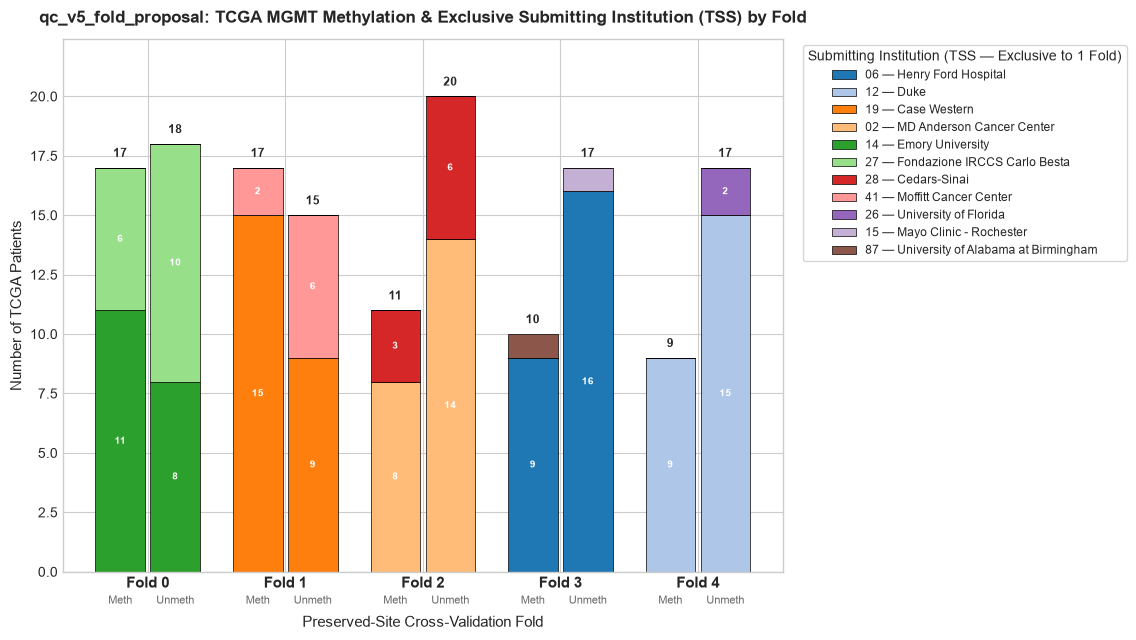

In [9]:
# --- 4. Render Stacked Bar Chart (Folds 0-4, Methylated vs Unmethylated, Colored by Institution) ---
folds = [str(i) for i in range(N_FOLDS)]
plot_df = tcga_df[tcga_df["new_fold"].isin(folds)].copy()

inst_order = (
    plot_df.groupby("institution")["patient_id"]
    .count()
    .sort_values(ascending=False)
    .index.tolist()
)
cmap = plt.get_cmap("tab20")
inst_colors = {inst: cmap(i % 20) for i, inst in enumerate(inst_order)}

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(11.5, 6.5))

x = np.arange(len(folds))
width = 0.36
shift = width / 2 + 0.02

for status, dx, tag in [("Methylated", -shift, "Meth"), ("Unmethylated", +shift, "Unmeth")]:
    sub = plot_df[plot_df["mgmt_clean"] == status]
    piv = (
        sub.groupby(["new_fold", "institution"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=folds, columns=inst_order, fill_value=0)
    )
    bottoms = np.zeros(len(folds))
    for inst in inst_order:
        vals = piv[inst].to_numpy(dtype=float)
        ax.bar(
            x + dx,
            vals,
            width=width,
            bottom=bottoms,
            color=inst_colors[inst],
            edgecolor="black",
            linewidth=0.5,
        )
        for i, v in enumerate(vals):
            if v >= 2:
                ax.text(
                    x[i] + dx,
                    bottoms[i] + v / 2,
                    f"{int(v)}",
                    ha="center",
                    va="center",
                    fontsize=7.5,
                    fontweight="bold",
                    color="white",
                )
        bottoms += vals
    for i, tot in enumerate(bottoms):
        if tot > 0:
            ax.text(
                x[i] + dx,
                tot + 0.35,
                f"{int(tot)}",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
            )
        ax.text(x[i] + dx, -1.0, tag, ha="center", va="top", fontsize=8, color="dimgray")

ax.set_xticks(x)
ax.set_xticklabels([f"Fold {f}" for f in folds], fontsize=10.5, fontweight="bold")
ax.set_xlabel("Preserved-Site Cross-Validation Fold", fontsize=11, labelpad=18)
ax.set_ylabel("Number of TCGA Patients", fontsize=11)
ax.set_title(
    "qc_v5_fold_proposal: TCGA MGMT Methylation & Exclusive Submitting Institution (TSS) by Fold",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.set_ylim(bottom=0, top=max(10, ax.get_ylim()[1] * 1.12))

handles = [
    Patch(facecolor=inst_colors[inst], edgecolor="black", linewidth=0.5, label=inst)
    for inst in inst_order
]
ax.legend(
    handles=handles,
    title="Submitting Institution (TSS — Exclusive to 1 Fold)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    fontsize=8.5,
)

plt.tight_layout()
chart_path = OUT_DIR / f"{PREFIX}_chart.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
print("Saved chart:", chart_path)
plt.show()

In [10]:
# --- 5. Build Per-Fold Macenko Reference Standard (25 Patches/Slide in Each Fold) ---
import io
from PIL import Image

MACENKO_OUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
patient_to_new_fold = dict(zip(tcga_df["patient_id"], tcga_df["new_fold"]))


def rgb_to_od(rgb: np.ndarray, Io: float = MACENKO_I0) -> np.ndarray:
  rgb_f = np.maximum(np.asarray(rgb, dtype=np.float64), 1.0)
  return -np.log(rgb_f / Io)


def fit_macenko_from_od_pool(
    od_pixels: np.ndarray,
    alpha: float = MACENKO_ALPHA,
    beta: float = MACENKO_BETA,
) -> tuple[np.ndarray, np.ndarray]:
  """Fit Macenko H&E stain matrix (2x3, rows=[H, E]) and 99th-percentile concentrations maxC (2,)."""
  mask = ~np.any(od_pixels <= beta, axis=1)
  od_hat = od_pixels[mask]
  if od_hat.shape[0] < 100:
    raise ValueError(
        f"Insufficient foreground OD pixels ({od_hat.shape[0]}) to fit Macenko"
        " reference."
    )

  cov = np.cov(od_hat.T)
  _, eigvecs = np.linalg.eigh(cov)
  V = eigvecs[:, [1, 2]]
  if V[0, 0] < 0:
    V[:, 0] *= -1
  if V[0, 1] < 0:
    V[:, 1] *= -1

  proj = od_hat @ V
  phi = np.arctan2(proj[:, 1], proj[:, 0])

  min_phi = np.percentile(phi, alpha)
  max_phi = np.percentile(phi, 100.0 - alpha)

  v_min = V @ np.array([np.cos(min_phi), np.sin(min_phi)])
  v_max = V @ np.array([np.cos(max_phi), np.sin(max_phi)])

  if v_min[0] > v_max[0]:
    HE = np.array([v_min, v_max], dtype=np.float64)
  else:
    HE = np.array([v_max, v_min], dtype=np.float64)

  HE /= np.linalg.norm(HE, axis=1, keepdims=True) + 1e-8

  C = od_hat @ np.linalg.pinv(HE)
  maxC = np.percentile(C, 99.0, axis=0)
  return HE, maxC


def find_image_dataset_in_h5(h5_obj: h5py.File) -> str | None:
  for cand in ["imgs", "patches", "images", "tiles", "data"]:
    if cand in h5_obj and isinstance(h5_obj[cand], h5py.Dataset):
      return cand
  for key in h5_obj.keys():
    item = h5_obj[key]
    if isinstance(item, h5py.Dataset) and item.ndim in (1, 3, 4):
      return key
  return None


def decode_single_item_to_rgb(item) -> np.ndarray | None:
  if item is None:
    return None
  if isinstance(item, (bytes, bytearray, memoryview, np.bytes_)):
    try:
      with Image.open(io.BytesIO(bytes(item))) as im:
        return np.asarray(im.convert("RGB"), dtype=np.uint8)
    except Exception:
      return None
  a = np.asarray(item)
  if a.dtype == object and a.size == 1:
    return decode_single_item_to_rgb(a.item())
  if a.dtype == object:
    return None
  if a.ndim == 1 and a.dtype == np.uint8:
    try:
      with Image.open(io.BytesIO(a.tobytes())) as im:
        return np.asarray(im.convert("RGB"), dtype=np.uint8)
    except Exception:
      return None
  if a.ndim == 2:
    a = np.repeat(a[..., None], 3, axis=-1)
  if a.ndim != 3 or a.shape[-1] < 3:
    return None
  a = a[..., :3]
  if a.dtype != np.uint8:
    a_f = a.astype(np.float32)
    max_val = float(np.nanmax(a_f)) if a_f.size > 0 else 0.0
    if max_val <= 1.0:
      a_f = a_f * 255.0
    a = np.clip(a_f, 0.0, 255.0).astype(np.uint8)
  return np.ascontiguousarray(a)


def read_h5_tiles_at_indices(h5_path: Path, indices: np.ndarray) -> list[np.ndarray]:
  out: list[np.ndarray] = []
  with h5py.File(h5_path, "r") as f:
    ds_name = find_image_dataset_in_h5(f)
    if ds_name is None:
      return out
    ds = f[ds_name]
    n_ds = ds.shape[0] if len(ds.shape) > 0 else 0
    if n_ds == 0:
      return out
    valid_idx = np.sort(np.unique(indices[(indices >= 0) & (indices < n_ds)]))
    if len(valid_idx) == 0:
      return out

    if ds.ndim == 4:
      batch = ds[valid_idx]
      if batch.shape[-1] == 4:
        batch = batch[..., :3]
      if batch.dtype != np.uint8:
        batch_f = batch.astype(np.float32)
        max_val = float(np.nanmax(batch_f)) if batch_f.size > 0 else 0.0
        if max_val <= 1.0:
          batch_f = batch_f * 255.0
        batch = np.clip(batch_f, 0.0, 255.0).astype(np.uint8)
      for i in range(batch.shape[0]):
        out.append(np.ascontiguousarray(batch[i]))
    else:
      for idx_i in valid_idx:
        rgb = decode_single_item_to_rgb(ds[int(idx_i)])
        if rgb is not None:
          out.append(rgb)
  return out


def resolve_h5_path(
    pkg_dir: Path, h5_rel_val, fallback_index: dict[str, Path]
) -> Path | None:
  if pd.isna(h5_rel_val):
    return None
  s = str(h5_rel_val).strip()
  if not s or s.lower() == "nan":
    return None
  p_raw = Path(s)
  candidates = [
      p_raw,
      pkg_dir / s,
      pkg_dir / "tiles" / s,
      pkg_dir / "h5" / s,
      PACKAGES_ROOT / s,
  ]
  for cand in candidates:
    if cand.exists() and cand.is_file() and not cand.name.startswith("._"):
      return cand
  by_name = fallback_index.get(p_raw.name)
  if by_name is not None and by_name.exists():
    return by_name
  return None


h5_fallback_by_name: dict[str, Path] = {}
for pkg in PACKAGE_NAMES:
  pkg_dir = PACKAGES_ROOT / pkg
  if pkg_dir.exists():
    for p in sorted(pkg_dir.rglob("*.h5")):
      if not p.name.startswith("._") and p.name not in h5_fallback_by_name:
        h5_fallback_by_name[p.name] = p

patch_tables = []
for pkg in PACKAGE_NAMES:
  pkg_dir = PACKAGES_ROOT / pkg
  mp_csv = pkg_dir / "modeling_patches.csv"
  if not mp_csv.exists():
    print(f"Warning: {mp_csv} not found, skipping.")
    continue
  df_mp = pd.read_csv(mp_csv, dtype={"fold": str}, low_memory=False)

  h5_col = next(
      (
          c
          for c in ["h5", "h5_path", "tile_h5", "h5_file", "file", "path"]
          if c in df_mp.columns
      ),
      None,
  )
  idx_col = next(
      (
          c
          for c in ["h5_index", "tile_index", "tile_idx", "index", "idx"]
          if c in df_mp.columns
      ),
      None,
  )
  if h5_col is None or idx_col is None:
    raise KeyError(
        f"Missing H5 path or index column in {mp_csv}. Found columns:"
        f" {list(df_mp.columns)}"
    )
  df_mp["_h5_rel"] = df_mp[h5_col]
  df_mp["_h5_idx"] = df_mp[idx_col]

  df_mp["patient_id"] = df_mp["patient_id"].astype(str).str.strip()
  df_mp["slide_id"] = df_mp["slide_id"].astype(str).str.strip()
  df_mp = df_mp[df_mp["patient_id"].isin(patient_to_new_fold)].copy()
  df_mp["new_fold"] = df_mp["patient_id"].map(patient_to_new_fold)
  if "stored" in df_mp.columns:
    df_mp = df_mp[
        df_mp["stored"].astype(str).str.lower().isin(["true", "1"])
    ].copy()
  if "role" in df_mp.columns:
    tissue_only = df_mp[df_mp["role"].astype(str).str.lower() == "tissue"]
    if len(tissue_only) > 0:
      df_mp = tissue_only.copy()
  df_mp["pkg_dir"] = str(pkg_dir)
  patch_tables.append(df_mp)

all_patches_df = (
    pd.concat(patch_tables, ignore_index=True)
    if patch_tables
    else pd.DataFrame()
)
print(
    f"Total stored TCGA tissue patches indexed across A & B: {len(all_patches_df)}"
)

macenko_records = []
for k_str in [str(i) for i in range(N_FOLDS)]:
  fold_patches = (
      all_patches_df[all_patches_df["new_fold"] == k_str].copy()
      if not all_patches_df.empty
      else pd.DataFrame()
  )
  slides_in_fold = (
      fold_patches["slide_id"].unique() if not fold_patches.empty else []
  )

  sampled_chunks = []
  if not fold_patches.empty:
    for _, grp in fold_patches.groupby("slide_id", sort=True):
      n_take = min(PATCHES_PER_SLIDE, len(grp))
      take_idx = rng.choice(grp.index.to_numpy(), size=n_take, replace=False)
      sampled_chunks.append(grp.loc[np.sort(take_idx)])

  sampled_df = (
      pd.concat(sampled_chunks, ignore_index=True)
      if sampled_chunks
      else pd.DataFrame()
  )
  od_pool = []
  patch_means = []
  missing_h5_count = 0
  empty_tile_count = 0

  if not sampled_df.empty:
    for (pkg_dir_str, h5_rel_val), h5_grp in sampled_df.groupby(
        ["pkg_dir", "_h5_rel"], sort=True, dropna=False
    ):
      h5_path = resolve_h5_path(
          Path(pkg_dir_str), h5_rel_val, h5_fallback_by_name
      )
      if h5_path is None:
        missing_h5_count += len(h5_grp)
        continue

      indices = (
          pd.to_numeric(h5_grp["_h5_idx"], errors="coerce")
          .dropna()
          .astype(int)
          .to_numpy()
      )
      if len(indices) == 0:
        empty_tile_count += len(h5_grp)
        continue

      try:
        imgs_list = read_h5_tiles_at_indices(h5_path, indices)
      except OSError:
        missing_h5_count += len(h5_grp)
        continue

      if not imgs_list:
        empty_tile_count += len(h5_grp)
        continue

      for img in imgs_list:
        patch_means.append(img.mean(axis=(0, 1)))
        flat_rgb = img.reshape(-1, 3)
        if flat_rgb.shape[0] > MAX_OD_PIXELS_PER_PATCH:
          pix_idx = rng.choice(
              flat_rgb.shape[0], size=MAX_OD_PIXELS_PER_PATCH, replace=False
          )
          flat_rgb = flat_rgb[pix_idx]
        od_pool.append(rgb_to_od(flat_rgb, Io=MACENKO_I0))

  if not od_pool:
    raise RuntimeError(
        f"No valid tissue OD pixels collected for Fold {k_str} "
        f"(sampled_rows={len(sampled_df)}, missing_h5_rows={missing_h5_count},"
        f" empty_tile_rows={empty_tile_count},"
        f" fallback_h5_indexed={len(h5_fallback_by_name)}). Verify"
        " /Volumes/Expansion is mounted and check h5 path/index columns."
    )

  od_all = np.vstack(od_pool)
  HE_ref, maxC_ref = fit_macenko_from_od_pool(
      od_all, alpha=MACENKO_ALPHA, beta=MACENKO_BETA
  )
  mean_rgb = (
      np.mean(patch_means, axis=0)
      if patch_means
      else np.zeros(3, dtype=np.float64)
  )

  npz_path = MACENKO_OUT_DIR / f"{PREFIX}_macenko_fold_{k_str}.npz"
  np.savez(
      npz_path,
      fold=np.array(k_str),
      HE_ref=HE_ref,
      stain_matrix_target=HE_ref,
      maxC_ref=maxC_ref,
      target_concentrations=maxC_ref,
      Io=np.array(MACENKO_I0),
      alpha=np.array(MACENKO_ALPHA),
      beta=np.array(MACENKO_BETA),
      n_slides=np.array(len(slides_in_fold)),
      n_patches_sampled=np.array(len(sampled_df)),
      patches_per_slide_target=np.array(PATCHES_PER_SLIDE),
      mean_rgb=mean_rgb,
      tss_codes=np.array(
          sorted(
              fold_patches["patient_id"]
              .apply(extract_tcga_tss)
              .dropna()
              .unique()
          )
      ),
  )

  macenko_records.append({
      "fold": k_str,
      "n_slides": len(slides_in_fold),
      "n_patches_sampled": len(sampled_df),
      "avg_patches_per_slide": round(
          len(sampled_df) / max(1, len(slides_in_fold)), 2
      ),
      "H_R": round(float(HE_ref[0, 0]), 5),
      "H_G": round(float(HE_ref[0, 1]), 5),
      "H_B": round(float(HE_ref[0, 2]), 5),
      "E_R": round(float(HE_ref[1, 0]), 5),
      "E_G": round(float(HE_ref[1, 1]), 5),
      "E_B": round(float(HE_ref[1, 2]), 5),
      "maxC_H": round(float(maxC_ref[0]), 5),
      "maxC_E": round(float(maxC_ref[1]), 5),
      "npz_path": str(npz_path),
  })
  print(
      f"Fold {k_str}: fitted Macenko reference from {len(sampled_df)} patches"
      f" across {len(slides_in_fold)} slides -> {npz_path.name}"
  )

macenko_summary_df = pd.DataFrame(macenko_records)
macenko_summary_path = OUT_DIR / f"{PREFIX}_macenko_summary.csv"
macenko_summary_df.to_csv(macenko_summary_path, index=False)
display(macenko_summary_df)

Total stored TCGA tissue patches indexed across A & B: 1427658
Fold 0: fitted Macenko reference from 2550 patches across 102 slides -> qc_v5_fold_proposal_macenko_fold_0.npz
Fold 1: fitted Macenko reference from 750 patches across 30 slides -> qc_v5_fold_proposal_macenko_fold_1.npz
Fold 2: fitted Macenko reference from 1000 patches across 40 slides -> qc_v5_fold_proposal_macenko_fold_2.npz
Fold 3: fitted Macenko reference from 1800 patches across 72 slides -> qc_v5_fold_proposal_macenko_fold_3.npz
Fold 4: fitted Macenko reference from 1850 patches across 74 slides -> qc_v5_fold_proposal_macenko_fold_4.npz


,fold,n_slides,n_patches_sampled,avg_patches_per_slide,H_R,H_G,H_B,E_R,E_G,E_B,maxC_H,maxC_E,npz_path
0,0,102,2550,25.0,0.57894,0.72631,0.37054,0.12543,0.76159,0.63581,2.93575,2.09346,/Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fol...
1,1,30,750,25.0,0.61019,0.70790,0.35573,0.14307,0.81999,0.55421,2.77662,1.98752,/Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fol...
2,2,40,1000,25.0,0.56711,0.75318,0.33333,0.12400,0.79730,0.59071,2.87332,2.29944,/Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fol...
3,3,72,1800,25.0,0.56443,0.74117,0.36344,0.10337,0.72880,0.67688,2.84687,2.29482,/Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fol...
4,4,74,1850,25.0,0.64590,0.69403,0.31802,0.10265,0.85977,0.50025,3.61552,2.99247,/Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fol...


In [9]:
# --- 6. Export Pipeline Manifests, JSON Reference Specs & Package Index Files (qc_v5_fold_proposal_*) ---
import hashlib
import json


def compute_file_sha256(path: Path) -> str:
  h = hashlib.sha256()
  with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
      h.update(chunk)
  return h.hexdigest()


patient_to_new_fold = dict(zip(tcga_df["patient_id"], tcga_df["new_fold"]))
fold_to_macenko_npz = dict(
    zip(macenko_summary_df["fold"], macenko_summary_df["npz_path"])
)

# Export matching .json sidecar files alongside each per-fold .npz reference
fold_to_macenko_json = {}
for rec in macenko_records:
  k_str = str(rec["fold"])
  npz_p = Path(rec["npz_path"])
  json_p = npz_p.with_suffix(".json")
  ref_data = np.load(npz_p)
  he_2x3 = np.asarray(ref_data["HE_ref"], dtype=float)
  maxc_2 = np.asarray(ref_data["maxC_ref"], dtype=float)
  mean_rgb_3 = (
      np.asarray(ref_data["mean_rgb"], dtype=float)
      if "mean_rgb" in ref_data
      else np.zeros(3, dtype=float)
  )
  tss_list = (
      [str(x) for x in ref_data["tss_codes"].tolist()]
      if "tss_codes" in ref_data
      else []
  )

  # Match schema conventions used by cohort_all_start.json / cohort_tcga_start.json / global_reference.json
  payload = {
      "name": f"{PREFIX}_macenko_fold_{k_str}",
      "fold": k_str,
      "sources": ["TCGA"],
      "packages": list(PACKAGE_NAMES),
      "seed": int(RANDOM_SEED),
      "patches_per_slide_target": int(PATCHES_PER_SLIDE),
      "n_slides": int(rec["n_slides"]),
      "n_patches_sampled": int(rec["n_patches_sampled"]),
      "avg_patches_per_slide": float(rec["avg_patches_per_slide"]),
      "tss_codes": tss_list,
      "Io": float(MACENKO_I0),
      "beta": float(MACENKO_BETA),
      "alpha": float(MACENKO_ALPHA),
      "mean_rgb": [round(float(v), 6) for v in mean_rgb_3.tolist()],
      "ref_HE_2x3": [[float(x) for x in row] for row in he_2x3.tolist()],
      "ref_HE": [[float(x) for x in col] for col in he_2x3.T.tolist()],
      "ref_max_C": [float(x) for x in maxc_2.tolist()],
      "maxC_ref": [float(x) for x in maxc_2.tolist()],
      "npz_path": str(npz_p),
      "npz_sha256": compute_file_sha256(npz_p),
  }
  with open(json_p, "w", encoding="utf-8") as jf:
    json.dump(payload, jf, indent=2)
  fold_to_macenko_json[k_str] = str(json_p)

macenko_summary_df["json_path"] = (
    macenko_summary_df["fold"].astype(str).map(fold_to_macenko_json)
)
macenko_summary_df.to_csv(macenko_summary_path, index=False)

# 6a. patient_folds -> qc_v5_fold_proposal_folds.csv
out_folds = folds_raw.copy()
out_folds["patient_id"] = out_folds["patient_id"].astype(str).str.strip()
out_folds["fold"] = out_folds["fold"].astype(str).str.strip()

if INCLUDE_EXTERNAL_IN_FILES:
  mask_mapped = out_folds["patient_id"].isin(patient_to_new_fold)
  out_folds.loc[mask_mapped, "fold"] = out_folds.loc[
      mask_mapped, "patient_id"
  ].map(patient_to_new_fold)
else:
  out_folds = out_folds[
      out_folds["patient_id"].isin(patient_to_new_fold)
  ].copy()
  out_folds["fold"] = out_folds["patient_id"].map(patient_to_new_fold)

out_folds["macenko_ref_npz"] = out_folds["fold"].map(fold_to_macenko_npz)
out_folds["macenko_ref_json"] = out_folds["fold"].map(fold_to_macenko_json)
folds_out_path = OUT_DIR / f"{PREFIX}_folds.csv"
out_folds.to_csv(folds_out_path, index=False)

# 6b. patient_labels -> qc_v5_fold_proposal_labels.csv
out_labels = labels_raw.copy()
out_labels["patient_id"] = out_labels["patient_id"].astype(str).str.strip()
if not INCLUDE_EXTERNAL_IN_FILES:
  out_labels = out_labels[
      out_labels["patient_id"].isin(patient_to_new_fold)
  ].copy()

labels_out_path = OUT_DIR / f"{PREFIX}_labels.csv"
out_labels.to_csv(labels_out_path, index=False)

# 6c. Master patient_index -> qc_v5_fold_proposal_index.csv
if MASTER_INDEX_CSV.exists():
  out_index = pd.read_csv(MASTER_INDEX_CSV, dtype={"fold": str}, low_memory=False)
  out_index["patient_id"] = out_index["patient_id"].astype(str).str.strip()
  if INCLUDE_EXTERNAL_IN_FILES:
    mask_idx = out_index["patient_id"].isin(patient_to_new_fold)
    out_index.loc[mask_idx, "fold"] = out_index.loc[
        mask_idx, "patient_id"
    ].map(patient_to_new_fold)
  else:
    out_index = out_index[
        out_index["patient_id"].isin(patient_to_new_fold)
    ].copy()
    out_index["fold"] = out_index["patient_id"].map(patient_to_new_fold)
  out_index["macenko_ref_npz"] = out_index["fold"].map(fold_to_macenko_npz)
  out_index["macenko_ref_json"] = out_index["fold"].map(fold_to_macenko_json)
  index_out_path = OUT_DIR / f"{PREFIX}_index.csv"
  out_index.to_csv(index_out_path, index=False)
  print("Saved master index:", index_out_path)

# 6d. Per-package index files inside A_qc-v5 and B_qc-v5 (qc_v5_fold_proposal_index.csv)
for pkg in PACKAGE_NAMES:
  pkg_dir = PACKAGES_ROOT / pkg
  p_idx = pkg_dir / "patient_index.csv"
  if p_idx.exists():
    df_p = pd.read_csv(p_idx, dtype={"fold": str}, low_memory=False)
    df_p["patient_id"] = df_p["patient_id"].astype(str).str.strip()
    mask_p = df_p["patient_id"].isin(patient_to_new_fold)
    df_p.loc[mask_p, "fold"] = df_p.loc[mask_p, "patient_id"].map(
        patient_to_new_fold
    )
    df_p["macenko_ref_npz"] = df_p["fold"].map(fold_to_macenko_npz)
    df_p["macenko_ref_json"] = df_p["fold"].map(fold_to_macenko_json)
    pkg_idx_out = pkg_dir / f"{PREFIX}_index.csv"
    df_p.to_csv(pkg_idx_out, index=False)
    print(f"Saved {pkg} index:", pkg_idx_out)

# 6e. Site-to-fold mapping audit table -> qc_v5_fold_proposal_site_summary.csv
site_summary_path = OUT_DIR / f"{PREFIX}_site_summary.csv"
site_stats.to_csv(site_summary_path, index=False)

print(
    "\nAll qc_v5_fold_proposal files & per-fold Macenko (.npz + .json)"
    " references generated successfully:"
)
for p in [
    folds_out_path,
    labels_out_path,
    site_summary_path,
    macenko_summary_path,
    chart_path,
]:
  print(" -", p)
for k_str, jp in sorted(fold_to_macenko_json.items()):
  print(f" - Fold {k_str} JSON: {jp}")

Saved master index: /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_index.csv
Saved A_qc-v5 index: /Volumes/Expansion/pathology_data/packages/A_qc-v5/qc_v5_fold_proposal_index.csv
Saved B_qc-v5 index: /Volumes/Expansion/pathology_data/packages/B_qc-v5/qc_v5_fold_proposal_index.csv

All qc_v5_fold_proposal files & per-fold Macenko references generated successfully:
 - /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_folds.csv
 - /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_labels.csv
 - /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_site_summary.csv
 - /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_macenko_summary.csv
 - /Users/couger/gbm-mgmt-wsi/manifests/qc_v5_fold_proposal_chart.png


Fold 0 | slide=8b207ebe-a391-4a52-afcc-0cd31f502673 | h5=8b207ebe-a391-4a52-afcc-0cd31f502673.h5 (idx=4806) | fg=99.2% | ref=qc_v5_fold_proposal_macenko_fold_0.npz
Fold 1 | slide=bd73b564-5ae1-4964-9e1b-697ea0d95a86 | h5=bd73b564-5ae1-4964-9e1b-697ea0d95a86.h5 (idx=2562) | fg=83.5% | ref=qc_v5_fold_proposal_macenko_fold_1.npz
Fold 2 | slide=2e7e2d0a-55d8-4c9d-b064-e8e65051b0ec | h5=2e7e2d0a-55d8-4c9d-b064-e8e65051b0ec.h5 (idx=2685) | fg=95.2% | ref=qc_v5_fold_proposal_macenko_fold_2.npz
Fold 3 | slide=43fb7edb-6c3b-46c6-b8b3-d43f96893236 | h5=43fb7edb-6c3b-46c6-b8b3-d43f96893236.h5 (idx=2345) | fg=91.9% | ref=qc_v5_fold_proposal_macenko_fold_3.npz
Fold 4 | slide=0148b9eb-68fe-4924-a4fb-b4508c21a1b4 | h5=0148b9eb-68fe-4924-a4fb-b4508c21a1b4.h5 (idx=1274) | fg=95.3% | ref=qc_v5_fold_proposal_macenko_fold_4.npz


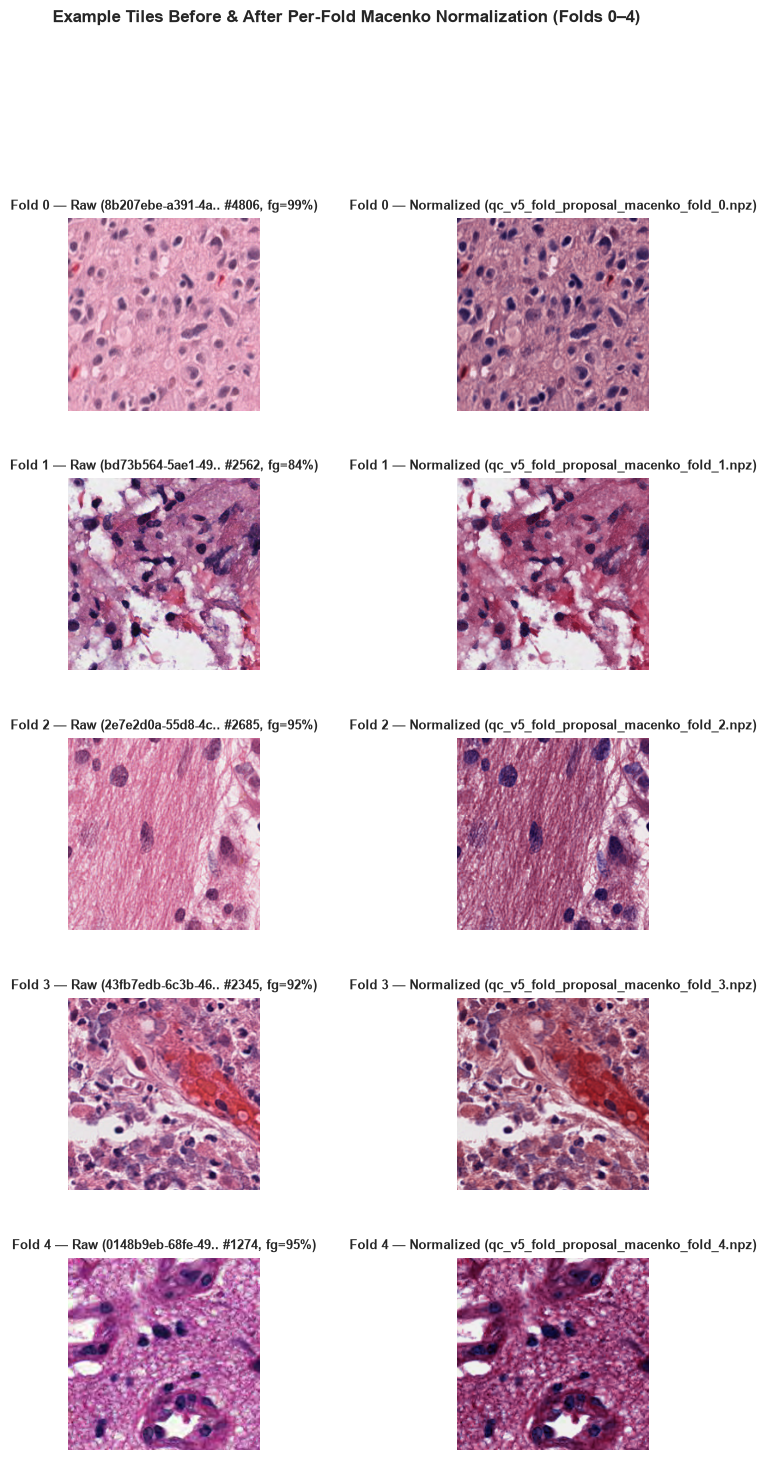

In [11]:
# --- 7. Visualize Raw vs. Per-Fold Macenko Normalized Example Tile (Folds 0-4) ---
from matplotlib.gridspec import GridSpec

FOLD_NORM_BETA = MACENKO_BETA
FOLD_NORM_CONC_PCT = 99.0
FOLD_NORM_SCALE_BOUNDS = (0.5, 2.0)


def od_to_rgb_fold(od: np.ndarray, Io: float = MACENKO_I0) -> np.ndarray:
  rgb_f = Io * np.exp(-np.clip(od, 0.0, 5.0))
  return np.clip(np.round(rgb_f), 0, 255).astype(np.uint8)


def normalize_with_fold_reference(
    rgb: np.ndarray,
    he_ref: np.ndarray,
    maxc_ref: np.ndarray,
    beta: float = FOLD_NORM_BETA,
    conc_pct: float = FOLD_NORM_CONC_PCT,
    scale_bounds: tuple[float, float] = FOLD_NORM_SCALE_BOUNDS,
) -> np.ndarray:
  """Normalize an (H, W, 3) uint8 RGB tile using that fold's Macenko HE_ref (2x3) and maxC_ref (2,)."""
  rgb_u8 = np.asarray(rgb, dtype=np.uint8)
  if rgb_u8.ndim != 3 or rgb_u8.shape[-1] != 3:
    raise ValueError(f"Expected (H, W, 3) uint8 tile, got {rgb_u8.shape}")

  orig_shape = rgb_u8.shape
  od = rgb_to_od(rgb_u8, Io=MACENKO_I0).reshape(-1, 3)
  norms = np.linalg.norm(od, axis=1)
  tissue_mask = norms > beta

  if tissue_mask.sum() < 50:
    return rgb_u8.copy()

  od_tissue = od[tissue_mask]

  # Estimate source stain matrix on the tile's tissue pixels; fall back to fold's he_ref if ill-conditioned
  src_stain = None
  if od_tissue.shape[0] >= 200:
    cov = np.cov(od_tissue.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    if eigvals[1] > 1e-6 and eigvals[2] > 1e-6:
      V = eigvecs[:, [1, 2]]
      if V[0, 0] < 0:
        V[:, 0] *= -1
      if V[0, 1] < 0:
        V[:, 1] *= -1
      proj = od_tissue @ V
      phi = np.arctan2(proj[:, 1], proj[:, 0])
      lo_phi = np.percentile(phi, MACENKO_ALPHA)
      hi_phi = np.percentile(phi, 100.0 - MACENKO_ALPHA)
      v_lo = V @ np.array([np.cos(lo_phi), np.sin(lo_phi)])
      v_hi = V @ np.array([np.cos(hi_phi), np.sin(hi_phi)])
      cand_he = np.array(
          [v_lo, v_hi] if v_lo[0] > v_hi[0] else [v_hi, v_lo],
          dtype=np.float64,
      )
      cand_he /= np.linalg.norm(cand_he, axis=1, keepdims=True) + 1e-8
      ang_deg = np.degrees(
          np.arccos(np.clip(np.dot(cand_he[0], cand_he[1]), -1.0, 1.0))
      )
      if np.linalg.cond(cand_he) < 25.0 and ang_deg >= 5.0:
        src_stain = cand_he

  if src_stain is None:
    src_stain = np.asarray(he_ref, dtype=np.float64)
    src_stain = src_stain / (
        np.linalg.norm(src_stain, axis=1, keepdims=True) + 1e-8
    )

  conc = np.maximum(od_tissue @ np.linalg.pinv(src_stain), 0.0)
  src_max_c = np.percentile(conc, conc_pct, axis=0)

  target_he = np.asarray(he_ref, dtype=np.float64)
  target_he = target_he / (
      np.linalg.norm(target_he, axis=1, keepdims=True) + 1e-8
  )
  target_max_c = np.asarray(maxc_ref, dtype=np.float64)

  scale = target_max_c / np.maximum(src_max_c, 1e-4)
  scale = np.clip(scale, scale_bounds[0], scale_bounds[1])

  od_norm = od.copy()
  od_norm[tissue_mask] = (conc * scale[None, :]) @ target_he
  return od_to_rgb_fold(od_norm, Io=MACENKO_I0).reshape(orig_shape)


folds_to_plot = [str(i) for i in range(N_FOLDS)]
vis_rng = np.random.default_rng(RANDOM_SEED + 100)

selected_examples = []
for k_str in folds_to_plot:
  npz_path = MACENKO_OUT_DIR / f"{PREFIX}_macenko_fold_{k_str}.npz"
  if not npz_path.exists():
    print(f"Warning: {npz_path} not found for Fold {k_str}; skipping.")
    continue

  ref_data = np.load(npz_path)
  he_ref = ref_data["HE_ref"]
  maxc_ref = ref_data["maxC_ref"]

  fold_rows = (
      all_patches_df[all_patches_df["new_fold"] == k_str]
      if "all_patches_df" in globals() and not all_patches_df.empty
      else pd.DataFrame()
  )
  if fold_rows.empty:
    print(f"Warning: No indexed patches for Fold {k_str}; skipping.")
    continue

  # Shuffle candidate patches in this fold and pick the first valid tissue-rich tile
  cand_indices = vis_rng.permutation(fold_rows.index.to_numpy())
  chosen_tile = None
  chosen_meta = None

  for r_idx in cand_indices[:200]:
    row = fold_rows.loc[r_idx]
    h5_path = resolve_h5_path(
        Path(row["pkg_dir"]), row["_h5_rel"], h5_fallback_by_name
    )
    if h5_path is None:
      continue
    tile_idx = pd.to_numeric(row["_h5_idx"], errors="coerce")
    if pd.isna(tile_idx):
      continue
    try:
      tiles = read_h5_tiles_at_indices(h5_path, np.array([int(tile_idx)]))
    except OSError:
      continue
    if not tiles:
      continue
    t_rgb = tiles[0]
    od_t = rgb_to_od(t_rgb, Io=MACENKO_I0).reshape(-1, 3)
    fg_frac = float((np.linalg.norm(od_t, axis=1) > FOLD_NORM_BETA).mean())
    if fg_frac >= 0.25:
      chosen_tile = t_rgb
      chosen_meta = (
          str(row["slide_id"]),
          int(tile_idx),
          fg_frac,
          h5_path.name,
      )
      break

  if chosen_tile is None:
    print(f"Warning: Could not decode a tissue-rich tile for Fold {k_str}.")
    continue

  norm_tile = normalize_with_fold_reference(chosen_tile, he_ref, maxc_ref)
  selected_examples.append((k_str, chosen_tile, norm_tile, chosen_meta, npz_path))
  slide_id, tile_idx, fg_frac, h5_name = chosen_meta
  print(
      f"Fold {k_str} | slide={slide_id} | h5={h5_name} (idx={tile_idx}) |"
      f" fg={fg_frac:.1%} | ref={npz_path.name}"
  )

if selected_examples:
  n_rows = len(selected_examples)
  fig = plt.figure(figsize=(9.5, 3.2 * n_rows))
  gs = GridSpec(n_rows, 2, figure=fig, wspace=0.12, hspace=0.35)

  for r_i, (k_str, raw_t, norm_t, meta, npz_p) in enumerate(selected_examples):
    slide_id, tile_idx, fg_frac, _ = meta

    ax_raw = fig.add_subplot(gs[r_i, 0])
    ax_raw.imshow(raw_t)
    ax_raw.set_title(
        f"Fold {k_str} — Raw ({slide_id[:16]}.. #{tile_idx}, fg={fg_frac:.0%})",
        fontsize=9.5,
        fontweight="bold",
    )
    ax_raw.axis("off")

    ax_norm = fig.add_subplot(gs[r_i, 1])
    ax_norm.imshow(norm_t)
    ax_norm.set_title(
        f"Fold {k_str} — Normalized ({npz_p.name})",
        fontsize=9.5,
        fontweight="bold",
    )
    ax_norm.axis("off")

  fig.suptitle(
      "Example Tiles Before & After Per-Fold Macenko Normalization (Folds 0–4)",
      fontsize=12,
      fontweight="bold",
      y=1.01,
  )
  plt.show()
else:
  print("No fold example tiles could be rendered.")